In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
# Validate configuration early
google_api_key = os.getenv("GOOGLE_API_KEY")
tavily_api_key = os.getenv("TAVILY_API_KEY")

if not google_api_key:
    raise ValueError("GOOGLE_API_KEY is missing")

if not tavily_api_key:
    raise ValueError("TAVILY_API_KEY is missing")

In [3]:
from typing import Literal
from tavily import TavilyClient
from deepagents import create_deep_agent
from langchain_google_genai import ChatGoogleGenerativeAI

In [4]:
llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0,
    api_key=os.getenv("GOOGLE_API_KEY"),
)

In [5]:
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

In [6]:
def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
) -> dict:
    """Search the internet using Tavily and return the search results."""
    return tavily_client.search(
        query=query,
        max_results=max_results,
        topic=topic,
        include_raw_content=include_raw_content,
    )

In [7]:
research_subagent = {
    "name": "research-agent",
    "description": (
        "Researches questions requiring current information, official "
        "documentation, APIs, SDK examples, or external sources. "
        "Delegate documentation research to this agent."
    ),
    "system_prompt": """
You are a web research specialist.

For questions about current documentation, APIs, SDKs, or recent
software versions:

1. You MUST call internet_search before answering.
2. Search for the official documentation first.
3. Search for a minimal, working example when appropriate.
4. Base your findings on the returned search results.
5. Clearly distinguish verified facts from anything uncertain.
6. Return a concise report with source URLs and relevant code examples.

Never claim that you cannot access the internet without first
attempting to use the internet_search tool.
""",
    "tools": [internet_search],
}

In [8]:
agent = create_deep_agent(
    model=llm,
    subagents=[research_subagent],
    system_prompt="""
You are an AI engineering assistant.

For questions asking about the latest documentation, current SDK
usage, recent API changes, or implementation examples based on
official documentation, delegate research to research-agent using
the task tool before drafting your answer.

Use the research report to formulate your final response.
Do not claim that you lack internet access when the research
subagent can search the web.

For other questions, answer normally when external research is
not necessary.
""",
)

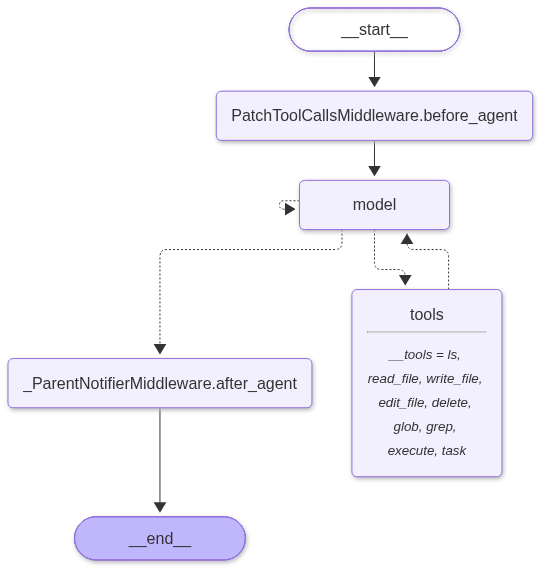

In [9]:
agent

In [10]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": (
                    "Research the latest official Claude Agent SDK "
                    "documentation. Show a minimal Python example "
                    "for building an agent, explain the important "
                    "parts, and include source URLs."
                ),
            }
        ]
    },
    config={"configurable": {"thread_id": "subagents-demo"}},
)

# Inspect messages and verify delegation/tool usage
for message in result["messages"]:
    message.pretty_print()

    tool_calls = getattr(message, "tool_calls", [])
    if tool_calls:
        print("TOOL CALLS:", tool_calls)


================================ Human Message =================================

Research the latest official Claude Agent SDK documentation. Show a minimal Python example for building an agent, explain the important parts, and include source URLs.
================================== Ai Message ==================================
Tool Calls:
  task (511545e9-3d3f-447a-ac7a-00db4503970a)
 Call ID: 511545e9-3d3f-447a-ac7a-00db4503970a
  Args:
    description: Research the latest official Claude Agent SDK documentation. Find a minimal Python example for building an agent, explain the important parts of the example, and include source URLs from the official documentation.
    subagent_type: research-agent
TOOL CALLS: [{'name': 'task', 'args': {'description': 'Research the latest official Claude Agent SDK documentation. Find a minimal Python example for building an agent, explain the important parts of the example, and include source URLs from the official documentation.', 'subagent_type': '

## Stuctured Output with SUBAGENTS

In [11]:
from pydantic import BaseModel, Field

class ResearchFindings(BaseModel):
    """Structured Findings from a research task"""
    summary: str = Field(description="Summary of findings")
    confidence: str = Field(description="Confidence score from 0 to 1")
    sources: list[str] = Field(description="List of source URLs")

In [12]:
research_subagent_sructured = {
    "name": "research-agent",
    "description": (
        "Researches questions requiring current information, official "
        "documentation, APIs, SDK examples, or external sources. "
        "Delegate documentation research to this agent."
    ),
    "system_prompt": """
You are a web research specialist.

For questions about current documentation, APIs, SDKs, or recent
software versions:

1. You MUST call internet_search before answering.
2. Search for the official documentation first.
3. Search for a minimal, working example when appropriate.
4. Base your findings on the returned search results.
5. Clearly distinguish verified facts from anything uncertain.
6. Return a concise report with source URLs and relevant code examples.

Never claim that you cannot access the internet without first
attempting to use the internet_search tool.
""",
    "tools": [internet_search],
    "response_format": ResearchFindings
}

In [14]:
agent_2 = create_deep_agent(
    model=llm,
    subagents=[research_subagent_sructured],
    system_prompt="""
You are an AI engineering assistant.

For questions asking about the latest documentation, current SDK
usage, recent API changes, or implementation examples based on
official documentation, delegate research to research-agent using
the task tool before drafting your answer.

Use the research report to formulate your final response.
Do not claim that you lack internet access when the research
subagent can search the web.

For other questions, answer normally when external research is
not necessary.
""",
)

In [17]:
result_2 = agent_2.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": (
                    "Research about the recent advancement in the field of quantum computing"
                ),
            }
        ]
    },
    config={"configurable": {"thread_id": "subagents-demo"}},
)

# Inspect messages and verify delegation/tool usage
for message in result_2["messages"]:
    message.pretty_print()

    tool_calls = getattr(message, "tool_calls", [])
    if tool_calls:
        print("TOOL CALLS:", tool_calls)


================================ Human Message =================================

Research about the recent advancement in the field of quantum computing
================================== Ai Message ==================================
Tool Calls:
  task (164a6115-791d-40b3-9669-b3a94e2a361c)
 Call ID: 164a6115-791d-40b3-9669-b3a94e2a361c
  Args:
    description: Research recent advancements in the field of quantum computing. Focus on breakthroughs in hardware, software, algorithms, and real-world applications. Summarize the key findings.
    subagent_type: research-agent
TOOL CALLS: [{'name': 'task', 'args': {'description': 'Research recent advancements in the field of quantum computing. Focus on breakthroughs in hardware, software, algorithms, and real-world applications. Summarize the key findings.', 'subagent_type': 'research-agent'}, 'id': '164a6115-791d-40b3-9669-b3a94e2a361c', 'type': 'tool_call'}]
================================= Tool Message =================================
N